In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

from sklearn.metrics import (average_precision_score, precision_score, recall_score, f1_score,
classification_report, confusion_matrix, ConfusionMatrixDisplay)

from sklearn.dummy import DummyClassifier
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42

# **Part A — Frame the problem before you look at any data**
## **A1 — The framing template**

**Problem:-**
* The bank wants to identify customers who are more likely to subscribe to a term deposit during its marketing campaigns.

**Decision:-**
* The marketing team can use the predicted scores to prioritize customers for outreach, subject to available staff and campaign capacity.

**User:-**
* The bank's direct-marketing team.

**Target:-**
* The y column, where yes means that the customer subscribed to a term deposit and no means that the customer did not subscribe.

**Unit:-**
* One row represents one recorded customer contact in the bank marketing dataset. The file does not provide a customer ID that would allow us to verify whether the same person appears in multiple records.

**Metric:-**
* Average Precision (AP). The positive class is relatively uncommon, so AP measures the quality of the ranking of likely subscribers without relying on accuracy alone.

**Baseline:-**
* A Constant-score ranking that assigns the same score to every customer. Its expected AP is approximately the positive-class prevalence, around 0.12 in the full dataset.
* The actual holdout baseline will be measured after splitting the data.

**Good Enough:-**
* As a provisional project target, achieve an AP at least 1.5 times the constant-score baseline on the chronological holdout.
* This is a project hypothesis, not a proven business threshold.
* Its usefullness must be checked again campaign costs, outreach capacity and the value of successful subscriptions.

**Failure:-**
* The project will not meet its objective if the model can't improve AP over the constant-score baseline on the holdout, or if its apparent performance depends on information that would not be available when the marketing team must decide whom to contact.

**False Positive Cost:-**
* A customer is prioritized but does not subscribe.
* This can waste staff time and marketing resources.

**False Negative Cost:-**
* A customer who would subscribe is not prioritized.
* This can mean a missed business opportunity.



This exact financial cost of either error is not provided by this dataset, so these costs can't yet be quantified ralibly.

## **A2 — Choose your metric from the decision, not from habit**

The target has two classes: `yes` or `no`. If relatively few clients subscribe, accuracy could look high even when a rule rarely identifies subcribers correctly.  
Average Precision evaluates the quality of a ranking by summarizing precision across different recall levels. It is useful when the team wants to prioritize a limited list of customers.

## **A3 — Decide your baseline now, not later**

Our baseline assigns the same score to every customer: the positive class proportion observed in the training set. It uses no customer-specific information.  
For an uninformative constant ranking, expected AP is approximately the proportion of positive examples.  
For example, if 12% of clients subscribed, the expected baseline AP would be about 0.12.

**Expected Baseline Score:-**
* The positive class rate calculated in A2, approximately.

**Good Enough Score:-**
* Provisional AP of 0.20 or higher, with a meaningful improvement over the measured baseline.

# **Part B — Interrogate the dataset before you commit to it**
## **B1 — Dataset selection**

**Dataset :-** Bank Marketing 
* The commonly distributed UCI Bank Marketing dataset describe direct-marketing campaigns coducted by a Portuguese banking instituition to promote term-deposite subscriptions. The data records customer characterstics, campaign information, and whether a subscription occured.}

**Potential limitation and bias :-**
* The records come from particular bank and campaign setting, so result may not transfer to other banks or time periods.
* Some customers may appear in multiple campaign observations.
* The target records the outcome of the contact; it does not necessarily represent a customer's long-term financial needs.
* Historical campaign decisions may have affected which customers were contacted, creating selection bias.
* Some columns may be unavailable at the time the bank must choose whom to contact.

In [2]:
# Load the csv
df = pd.read_csv("../data/bank-full.csv", sep=";")

print("Dataset Loaded Successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

display(df.head())

Dataset Loaded Successfully!
Number of rows: 45211
Number of columns: 17


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [3]:
# Check the columns and data types 
print("Column Names:")
print(df.columns.tolist())
print("\nDatatypes:")
print(df.dtypes)
print("\nDataset Information:")
df.info()

Column Names:
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']

Datatypes:
age          int64
job            str
marital        str
education      str
default        str
balance      int64
housing        str
loan           str
contact        str
day          int64
month          str
duration     int64
campaign     int64
pdays        int64
previous     int64
poutcome       str
y              str
dtype: object

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        45211 non-null  int64
 1   job        45211 non-null  str  
 2   marital    45211 non-null  str  
 3   education  45211 non-null  str  
 4   default    45211 non-null  str  
 5   balance    45211 non-null  int64
 6   housing    45211 non-null  str  
 7   l

**Source :-** From Kaggel UCI Bank Marketing dataset  
**Collection Content :-** Historical bank marketing campaigns  
**Purpose :-** Understand and improve targeting for term-deposit marketing.  
**Limitations :-** Campaign-specific data, possible repeated customers, potential selection bias, and possible leakage from post-contact information.

## **B2 — The five checks that disqualify a dataset**

In [4]:
# Check the target 
target = "y"

print("Target column exists:", target in df.columns)

print("\nTarget Values:")
print(df[target].value_counts())

print("\nTarget Percentage:")
print((df[target].value_counts(normalize=True) * 100).round(2))

Target column exists: True

Target Values:
y
no     39922
yes     5289
Name: count, dtype: int64

Target Percentage:
y
no     88.3
yes    11.7
Name: proportion, dtype: float64


In [5]:
# Check missing values and duplicates
print("Total missing values:", df.isnull().sum().sum())

print("\nMissing values by columns:")
print(df.isnull().sum().sort_values(ascending=False))

print("\nExact duplicate rows:", df.duplicated().sum())

print("\nNumber of unique values per column:")
print(df.nunique())

Total missing values: 0

Missing values by columns:
age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64

Exact duplicate rows: 0

Number of unique values per column:
age            77
job            12
marital         3
education       4
default         2
balance      7168
housing         2
loan            2
contact         3
day            31
month          12
duration     1573
campaign       48
pdays         559
previous       41
poutcome        4
y               2
dtype: int64


In [6]:
# check whether the target is defined
print("Unique target values:", df["y"].unique())

assert set(df["y"].unique()) == {"yes", "no"}

print("Target is clearly defined as yes/no.")

Unique target values: <StringArray>
['no', 'yes']
Length: 2, dtype: str
Target is clearly defined as yes/no.


**Check 1 — Is the target actually there, and is it well defined?**  
Ans. The target exists in the y column and indicates whether the customer subscribed to a term deposit. The dataset's documentation identifies this as the outcome of the marketing contact.

In [7]:
# Check dataset size 
class_count = df["y"].value_counts()

print("Total Rows:", len(df))
print("Negative Cases:", class_count["no"])
print("Positive Cases:", class_count["yes"])
print("Minority-class percentage:", round(class_count["yes"] / len(df) * 100, 2), "%")

Total Rows: 45211
Negative Cases: 39922
Positive Cases: 5289
Minority-class percentage: 11.7 %


**Check 2 — Is there enough of it?**  
Ans. The dataset has 45,211 records and 5,289 positive cases. This is sufficient for an initial classification project, although the minority class and the possibility of distribution shift need to be considered.

In [8]:
# Investigate possible leakage
print("Columns in dataset:")
for col in df.columns:
    print("-", col)

print("\nColumns requiring special attention:")
print("duration:", "Call duration; known after the call.")
print("poutcome:", "Outcome of a previous marketing campaign.")
print("pdays:", "Days since the customer was previously contacted.")
print("previous:", "Number of contacts before this campaign.")
print("day/month:", "Calendar components; no year is provided.")

Columns in dataset:
- age
- job
- marital
- education
- default
- balance
- housing
- loan
- contact
- day
- month
- duration
- campaign
- pdays
- previous
- poutcome
- y

Columns requiring special attention:
duration: Call duration; known after the call.
poutcome: Outcome of a previous marketing campaign.
pdays: Days since the customer was previously contacted.
previous: Number of contacts before this campaign.
day/month: Calendar components; no year is provided.


**Check 3 — Does a column leak the answer?**  
Ans. `duration` is the clearest leakage risk for a model intended to prioritize customers before calling them. We will exclude it. `poutcome`, `pdays`, and `previous` describe prior campaign history and may be usable if they are available at decision time. We will verify this assumption with the data owner before any real deployment.

In [9]:
# Check the Dimension
print("Date-related columns: day, month")

print("Month Values:")
print(df["month"].value_counts())

print("\nFirst 10 date components:")
display(df[['day', "month"]].head(10))

print("\nLast 10 date components:")
display(df[["day", "month"]].tail(10))

print("\nTarget rate in consecutive portions of the file:")
df["positive_target"] = (df["y"] == "yes").astype(int)

df["row_period"] = pd.qcut(np.arange(len(df)), q=5, labels=["Period 1", "Period 2", "Period 3", "Period 4", "Period 5"])

display(df.groupby("row_period", observed=True)["positive_target"]
       .agg(["count", "mean"])
       .rename(columns={"count": "rows", "mean": "positive_rate"}))

Date-related columns: day, month
Month Values:
month
may    13766
jul     6895
aug     6247
jun     5341
nov     3970
apr     2932
feb     2649
jan     1403
oct      738
sep      579
mar      477
dec      214
Name: count, dtype: int64

First 10 date components:


,day,month
0,5,may
1,5,may
2,5,may
3,5,may
4,5,may
5,5,may
6,5,may
7,5,may
8,5,may
9,5,may



Last 10 date components:


,day,month
45201,17,nov
45202,17,nov
45203,17,nov
45204,17,nov
45205,17,nov
45206,17,nov
45207,17,nov
45208,17,nov
45209,17,nov
45210,17,nov



Target rate in consecutive portions of the file:


,rows,positive_rate
row_period,,
Period 1,9043,0.033617
Period 2,9042,0.056182
Period 3,9042,0.061380
Period 4,9042,0.117894
Period 5,9042,0.315859


**Check 4 — Is there a time dimension?**  
Ans. The dataset contains day and month, but not a complete timestamp or year. The supplied records appear to follow a time-related sequence. For this assignment, we will preserve the original row order for a holdout split rather than shuffle records randomly. The absence of a year means the exact dates and duration of the holdout period cannot be independently reconstructed from these columns alone.

In [10]:
# Human predictability check
sample = df.sample(10, random_state=42)

human_check = sample.drop(
    columns=["y", "positive_target", "row_period"],
    errors="ignore"
)

print("Ten records with target hidden:")
display(human_check)

print("\nActual labels -- reveal only after attempting the guesses:")
display(sample[["y"]])

Ten records with target hidden:


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome
3776,40,blue-collar,married,secondary,no,580,yes,no,unknown,16,may,192,1,-1,0,unknown
9928,47,services,single,secondary,no,3644,no,no,unknown,9,jun,83,2,-1,0,unknown
33409,25,student,single,tertiary,no,538,yes,no,cellular,20,apr,226,1,-1,0,unknown
31885,42,management,married,tertiary,no,1773,no,no,cellular,9,apr,311,1,336,1,failure
15738,56,management,married,tertiary,no,217,no,yes,cellular,21,jul,121,2,-1,0,unknown
30813,28,blue-collar,married,secondary,no,1134,no,no,cellular,9,feb,130,3,-1,0,unknown
35463,24,management,single,tertiary,no,1085,no,yes,cellular,7,may,95,6,-1,0,unknown
31382,37,admin.,single,secondary,no,127,no,no,cellular,23,mar,83,4,-1,0,unknown
16904,30,blue-collar,single,secondary,no,3,yes,no,cellular,25,jul,51,1,-1,0,unknown
11930,38,technician,single,secondary,no,258,no,yes,unknown,20,jun,587,2,-1,0,unknown



Actual labels -- reveal only after attempting the guesses:


,y
3776,no
9928,no
33409,no
31885,no
15738,no
30813,no
35463,no
31382,no
16904,no
11930,no


**Check 5 — Can a person do this task?**  
Ans. A person can form plausible guesses using customer characteristics and previous campaign history, but cannot know the outcome with certainty. This supports trying an ML approach; it does not prove that the available features will provide useful predictive performance.

# **Part D — EDA that answers your own questions**

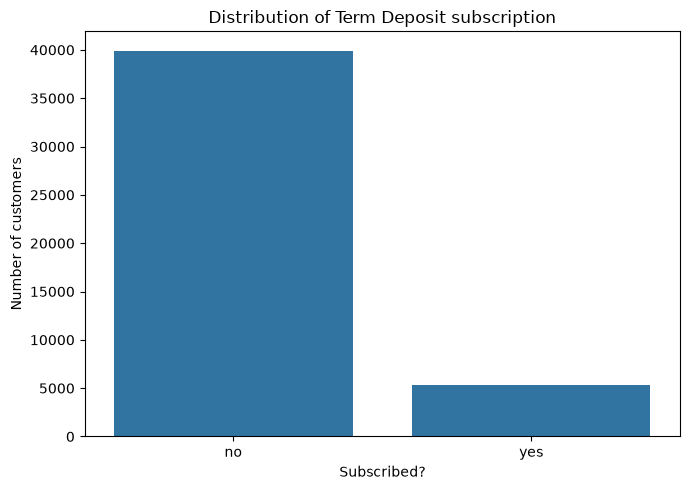

y
no     39922
yes     5289
Name: count, dtype: int64
y
no     88.3
yes    11.7
Name: proportion, dtype: float64


In [11]:
# Target Distribution
eda_df = pd.read_csv("../data/bank-full.csv", sep=";")

fig, ax = plt.subplots(figsize=(7, 5))
sns.countplot(data=eda_df, x="y")

ax.set_title("Distribution of Term Deposit subscription")
ax.set_xlabel("Subscribed?")
ax.set_ylabel("Number of customers")

plt.tight_layout()
plt.show()

print(eda_df["y"].value_counts())
print((eda_df["y"].value_counts(normalize=True) * 100).round(2))

**Interpretation :-** Most records belong to the no class. This imbalance is why accuracy alone would not be a sufficient evaluation metric.

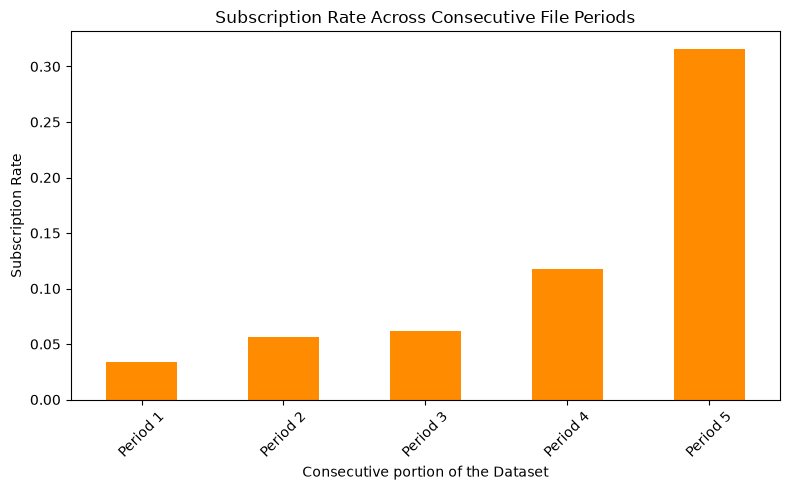

period
Period 1    0.0336
Period 2    0.0562
Period 3    0.0614
Period 4    0.1179
Period 5    0.3159
Name: positive, dtype: float64


In [12]:
# Check the target across time-related portions
eda_df["positive"] = (eda_df['y'] == 'yes').astype(int)

eda_df["period"] = pd.qcut(np.arange(len(eda_df)), q=5,
                          labels=["Period 1", "Period 2", "Period 3", "Period 4", "Period 5"])

period_rates = eda_df.groupby("period", observed=True)["positive"].mean()

fig, ax = plt.subplots(figsize=(8, 5))
period_rates.plot(kind="bar", color="darkorange")

ax.set_title("Subscription Rate Across Consecutive File Periods")
ax.set_xlabel("Consecutive portion of the Dataset")
ax.set_ylabel("Subscription Rate")
ax.tick_params(axis="x", labelrotation=45)

plt.tight_layout()
plt.show()

print(period_rates.round(4))

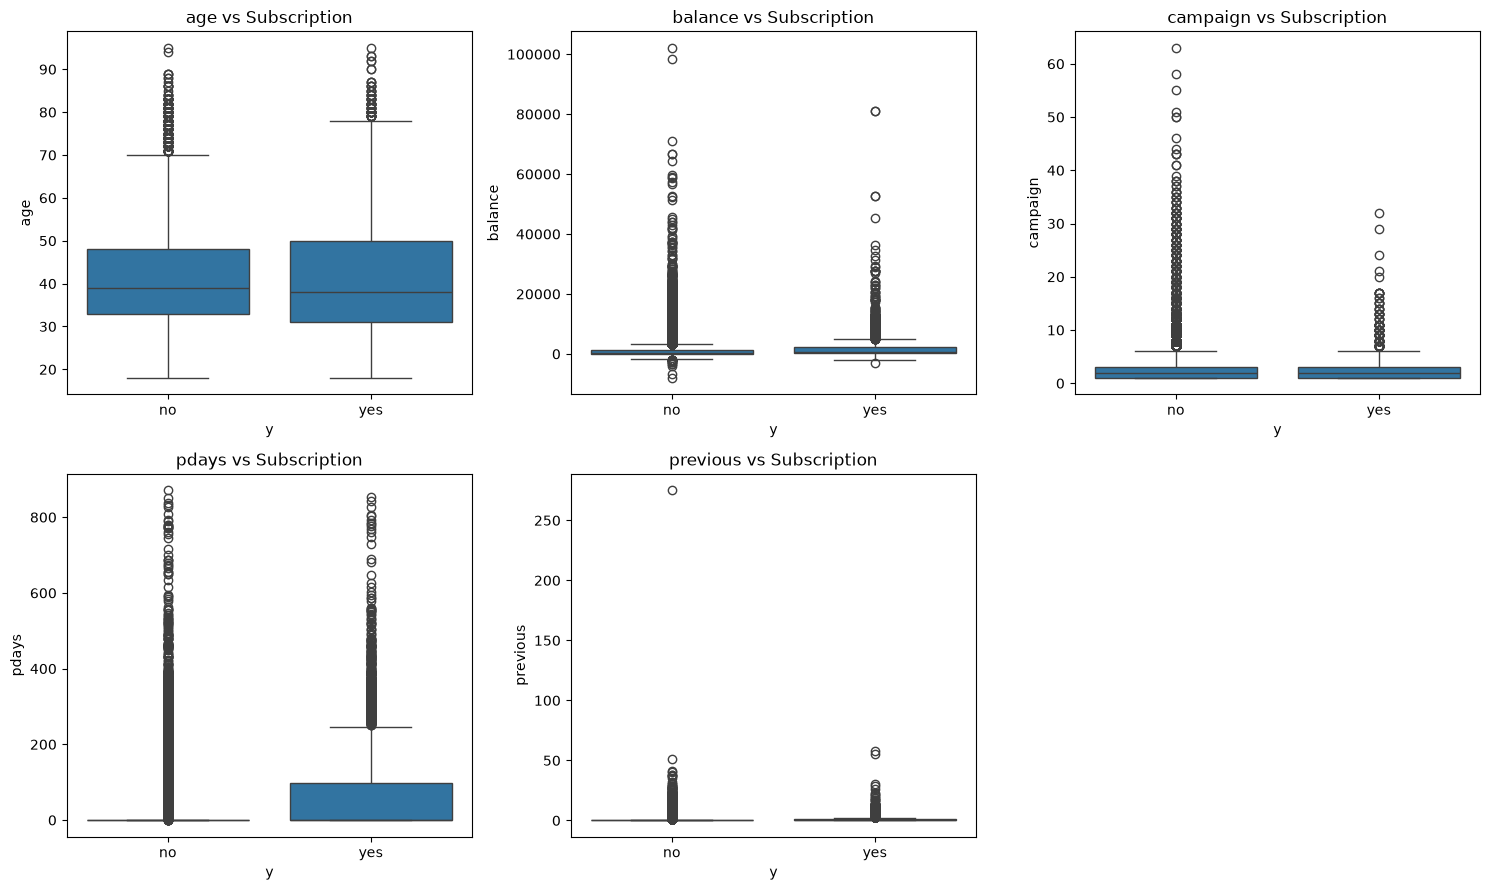

In [14]:
# Numeric feature relationships
numeric_features = ["age", "balance", "campaign", "pdays", "previous"]

fig, ax = plt.subplots(2, 3, figsize=(15, 9))
ax = ax.flatten()

for i, col in enumerate(numeric_features):
    sns.boxplot(data=eda_df, x="y", y=col, ax=ax[i])
    ax[i].set_title(f"{col} vs Subscription")

ax[-1].axis("off")

plt.tight_layout()
plt.show()

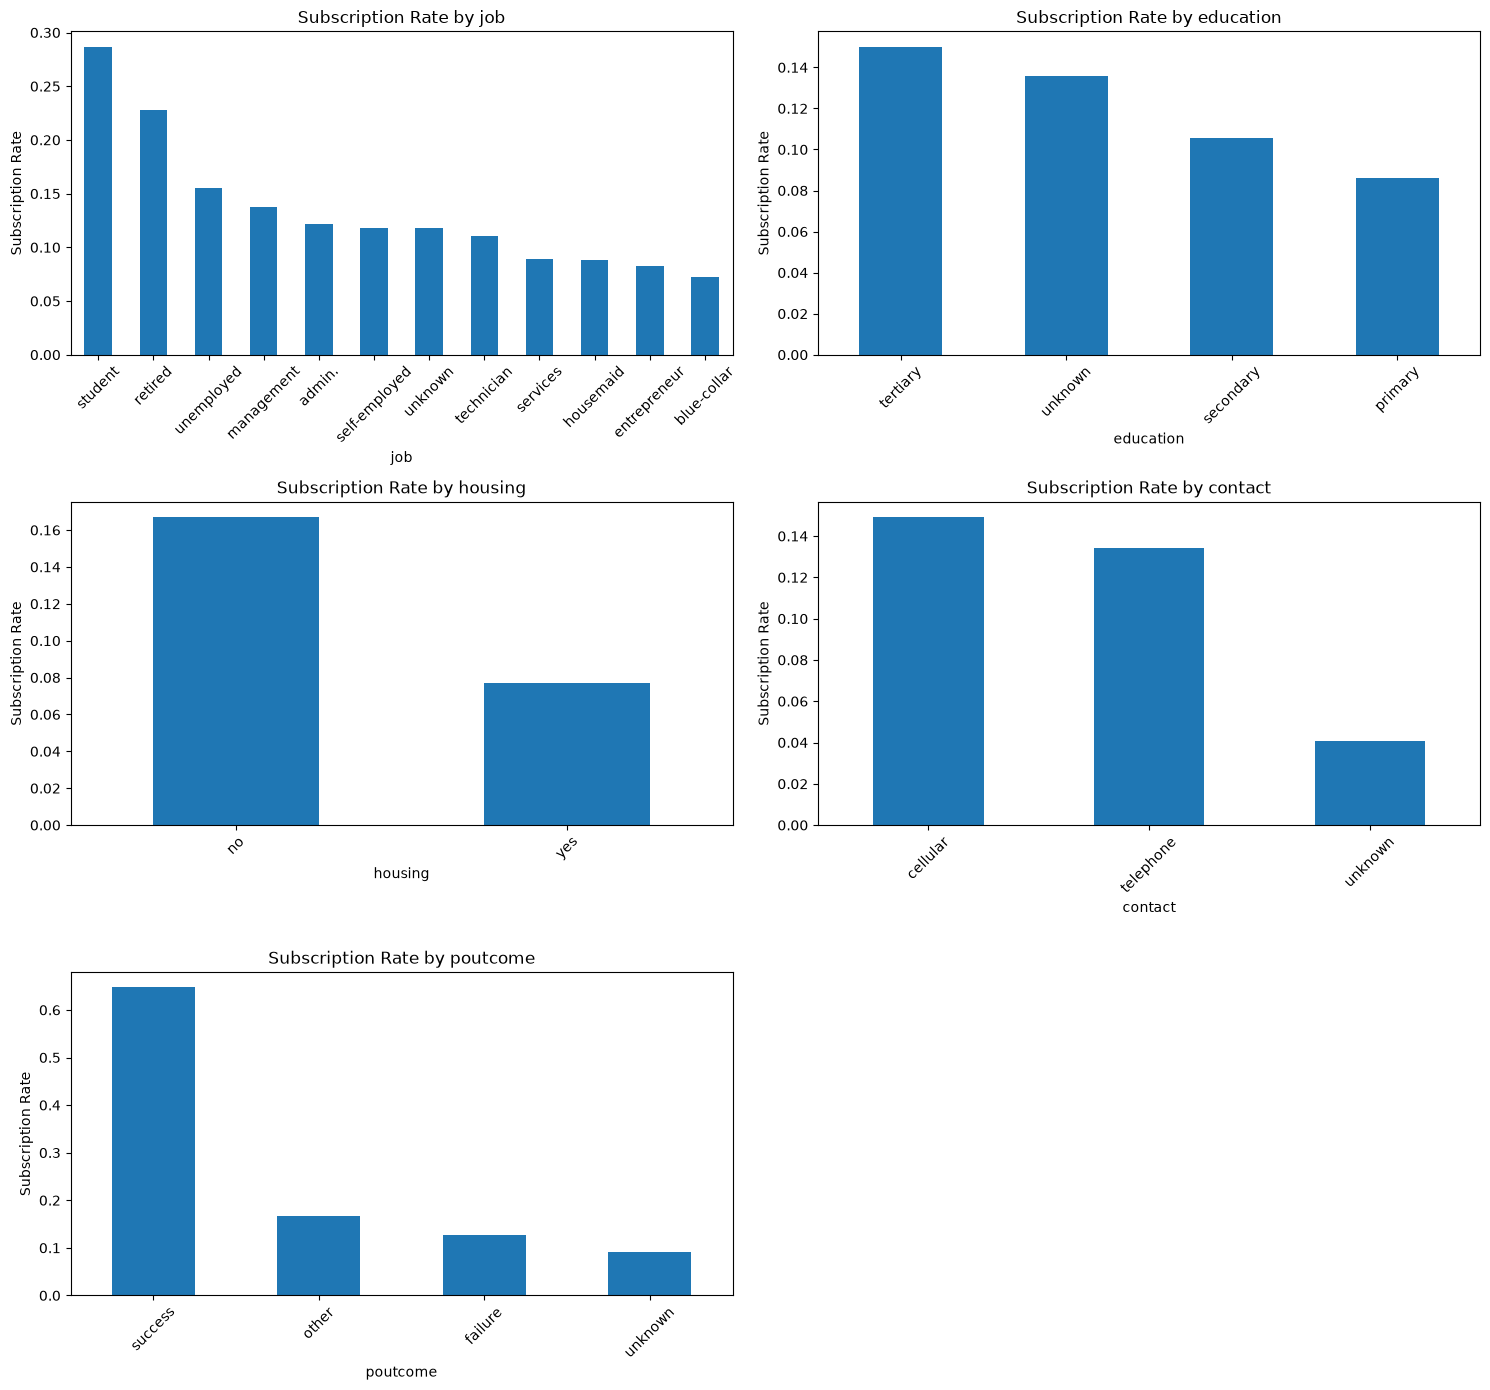

In [15]:
# Categorical feature relations
categorical_features = ["job", "education", "housing", "contact", "poutcome"]

fig, ax = plt.subplots(3, 2, figsize=(15, 14))
ax = ax.flatten()

for i, col in enumerate(categorical_features):
    rate = (eda_df.groupby(col, observed=True)["positive"]
           .mean()
           .sort_values(ascending=False))

    rate.plot(kind="bar", ax=ax[i])
    ax[i].set_title(f"Subscription Rate by {col}")
    ax[i].set_xlabel(col)
    ax[i].set_ylabel("Subscription Rate")
    ax[i].tick_params(axis="x", rotation=45)

ax[-1].axis("off")

plt.tight_layout()
plt.show()

In [16]:
# missing values and suspicious values
missing_counts = eda_df.isnull().sum()

print("Missing Values:")
print(missing_counts[missing_counts > 0])

Missing Values:
Series([], dtype: int64)


In [25]:
print("Unknown Category Counts:")
print("-" * 25)

for col in eda_df.select_dtypes(include="object").columns:
    if col != "y":
        unknown_count = (eda_df[col] == "unknown").sum()
        if unknown_count > 0:
            print(f"{col}: {unknown_count}")


print("\nSpecial values in pdays:")
print("-" * 25)
print(eda_df["pdays"].value_counts().head(10))

print("\nDescriptive statistics:")
print("-" * 25)
print(eda_df.describe(include="all").T)

Unknown Category Counts:
-------------------------
job: 288
education: 1857
contact: 13020
poutcome: 36959

Special values in pdays:
-------------------------
pdays
-1      36954
 182      167
 92       147
 91       126
 183      126
 181      117
 370       99
 184       85
 364       77
 95        74
Name: count, dtype: int64

Descriptive statistics:
-------------------------
             count unique          top   freq         mean          std  \
age        45211.0    NaN          NaN    NaN     40.93621    10.618762   
job          45211     12  blue-collar   9732          NaN          NaN   
marital      45211      3      married  27214          NaN          NaN   
education    45211      4    secondary  23202          NaN          NaN   
default      45211      2           no  44396          NaN          NaN   
balance    45211.0    NaN          NaN    NaN  1362.272058  3044.765829   
housing      45211      2          yes  25130          NaN          NaN   
loan         45211

In [34]:
# EDA Findings
print("EDA SUMMARY")
print("-" * 13)

print("Rows:", len(eda_df))
print("Columns:", eda_df.shape[1])
print("Missing Values:", eda_df.isnull().sum().sum())
print("Duplicate Rows:", eda_df.duplicated().sum())
print("Positive Rate:", round(eda_df["positive"].mean(), 4))

print("\nSubscription rate by previous outcome:")
print("-" * 40)
print(eda_df.groupby("poutcome", observed=True)["positive"]
     .agg(["count", "mean"])
     .sort_values("mean", ascending=False)
     .round(4))

EDA SUMMARY
-------------
Rows: 45211
Columns: 19
Missing Values: 0
Duplicate Rows: 0
Positive Rate: 0.117

Subscription rate by previous outcome:
----------------------------------------
          count    mean
poutcome               
success    1511  0.6473
other      1840  0.1668
failure    4901  0.1261
unknown   36959  0.0916


**EDA Findings :-**  
* The target distribution is imbalanced, with fewer customers subscribing than not subscribing. This supports using Average Precision rather than accuracy as the primary metric.
* The numeric and categorical plots are used to investigate whether customer characteristics and prior campaign history have potentially useful relationships with subscription outcomes. The results must be interpreted as associations rather than causal effects.
* Missing values, exact duplicate rows and special values are checked separately. In particular, unknown categories and the pdays = -1 code should be understood before preprocessing.
* The target rate is also examined across consecutive portions of the source file. If the rate differs substantially between portions, the chronological holdout may represent a different distribution from the training data. This must be considered when interpreting the baseline and any future model.
* The original framing remains provisional until the holdout baseline is measured. Any observed change in the target rate or any evidence of leakage must be documented before proceeding.

# **Part E — Build the baseline today**

In [35]:
# Create the time aware train/test split
baseline_df = pd.read_csv("../data/bank-full.csv", sep=";")
split_index = int(len(baseline_df) * 0.80)

train = baseline_df.iloc[:split_index].copy()
test = baseline_df.iloc[split_index:].copy()

y_train = (train["y"] == "yes").astype(int)
y_test = (test["y"] == "yes").astype(int)

print("Training Rows:", len(train))
print("Testing Rows:", len(test))

print("\nTraining subscription rate:")
print(round(y_train.mean(), 4))
print("Testing subscription rate:")
print(round(y_test.mean(), 4))

print("\nTraining period boundaries:")
print(train[["day", "month"]].iloc[[0, -1]])
print("\nTesting period boundaries:")
print(test[["day", "month"]].iloc[[0, -1]])

Training Rows: 36168
Testing Rows: 9043

Training subscription rate:
0.0673
Testing subscription rate:
0.3158

Training period boundaries:
       day month
0        5   may
36167   11   may

Testing period boundaries:
       day month
36168   11   may
45210   17   nov


In [38]:
# Baseline 1: Constant score
dummy = DummyClassifier(strategy="prior")

X_train_dummy = np.zeros((len(train), 1))
X_test_dummy = np.zeros((len(test), 1))

dummy.fit(X_train_dummy, y_train)

baseline_scores = dummy.predict_proba(X_test_dummy)[:, 1]

baseline_ap = average_precision_score(y_test, baseline_scores)

print("Constant-score Baseline AP:", round(baseline_ap, 4))
print("Expected AP before evaluation: approximately 0.12")

Constant-score Baseline AP: 0.3158
Expected AP before evaluation: approximately 0.12


In [48]:
# Baseline 2: simple campaign-history rule
poutcome_score_map = {
    "success": 1.0,
    "failure": 0.5,
    "other": 0.0,
    "unknown": 0.0
}

simple_scores = test["poutcome"].map(poutcome_score_map).fillna(0.0)
simple_ap = average_precision_score(y_test, simple_score)

print("Campaign-history Rule AP:", round(simple_ap, 4))

Campaign-history Rule AP: 0.4484


In [49]:
# Compare the baselines
baseline_results = pd.DataFrame({
    "Method": ["Constant-score baseline", "Campaign-history rule"],
    "Average Precision": [baseline_ap, simple_ap]
})

baseline_results["improvement over constant baseline"] = (
    baseline_results["Average Precision"] / baseline_ap
)

display(baseline_results.round(4))

,Method,Average Precision,improvement over constant baseline
0,Constant-score baseline,0.3158,1.0000
1,Campaign-history rule,0.4484,1.4198


In [50]:
print("Provisional good-enough AP threshold:",
     round(1.5 * baseline_ap, 4))

Provisional good-enough AP threshold: 0.4737


Precision: 0.3915
Recall: 0.4832
F1-Score: 0.4325

Classification report:
                 precision    recall  f1-score   support

no subscription       0.73      0.65      0.69      6187
   subscription       0.39      0.48      0.43      2856

       accuracy                           0.60      9043
      macro avg       0.56      0.57      0.56      9043
   weighted avg       0.62      0.60      0.61      9043



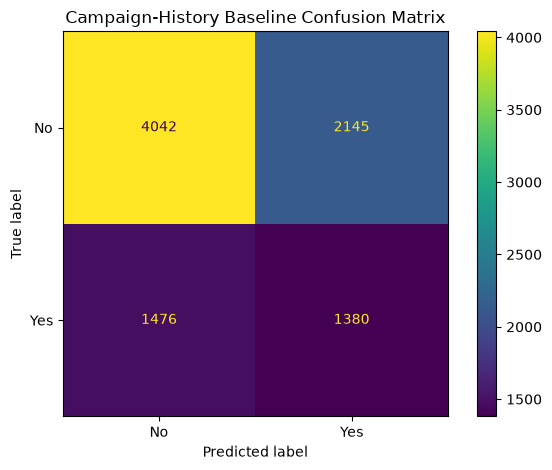

In [53]:
# Report baseline classification errors
simple_prediction = (simple_scores >= 0.5).astype(int)

print("Precision:", round(precision_score(y_test, simple_prediction, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, simple_prediction, zero_division=0), 4))
print("F1-Score:", round(f1_score(y_test, simple_prediction, zero_division=0), 4))

print("\nClassification report:")
print(classification_report(y_test, simple_prediction, target_names=["no subscription", "subscription"],
                           zero_division=0))

ConfusionMatrixDisplay.from_predictions(y_test, simple_prediction, display_labels=["No", "Yes"])

plt.title("Campaign-History Baseline Confusion Matrix")
plt.tight_layout()
plt.show()

# **Part F — The scoping review**

## 1. Problem, Decision, and User
**Problem:** The bank needs to use its marketing resources more effectively by identifying customers who are more likely to subscribe to a term deposit.  
**Decision:** Prioritize customers for telephone outreach based on their predicted likelihood of subscribing.  
**User:** The bank's marketing team.

## 2. Target and Unit of Analysis
**Target:** `y`, which indicates whether a customer subscribed to a term deposit (`yes` or `no`).  
**Unit of analysis:** One recorded campaign observation.

## 3. Evaluation Metric
**Metric:** Average Precision (AP).
Average Precision is appropriate because the positive class is relatively uncommon and the bank needs to rank likely subscribers near the top of the outreach list. AP evaluates the precision-recall trade-off across different ranking thresholds.

## 4. Baseline
**Baseline method:** Assign every test observation the positive-class rate calculated from the training data as its score.  
**Expected baseline:** A simple reference that a useful model should improve upon.  
**Measured baseline AP:**  0.4737

## 5. Five Scoping Checks
1. **Is the decision clear?**  
Yes. The goal is to prioritize customers for telephone outreach.
2. **Is the target defined?**    
Yes. The target is `y`, indicating term-deposit subscription.
3. **Is the evaluation metric appropriate?**  
Average Precision is suitable for evaluating a ranked list when positive outcomes are relatively uncommon.
4. **Could there be data leakage?**  
Yes. The `duration` feature records call duration, which is not known before a call begins. It should be excluded from a model intended to prioritize customers before outreach. Other features should also be checked for availability at prediction time.
5. **What are the main limitations?**  
The dataset may contain repeated observations, unknown category values, selection bias, and historical campaign patterns that may not generalize to future campaigns.

## 6. Leakage Decision
The `duration` feature will be excluded from the pre-outreach model because it is only known after a call has started. Including it would make the evaluation unrealistic for the intended business decision.

## 7. Failure Conditions
The project would fail to meet its objective if the required features were unavailable before outreach, the target were unreliable, or the model did not meaningfully improve on the baseline.

## 8. Hardest Part
The most important challenge is ensuring that the features used by the model would genuinely be available at the time the bank needs to make its outreach decision.

## 9. Scope Reduction
If only one day remained, I would prioritize validating the target and data split, removing leakage-prone features, establishing a reliable baseline, and documenting the results. I would postpone extensive hyperparameter tuning and advanced model comparisons.